# Global Solution 2026/2 — Vaga Viva

**Disciplina:** Artificial Intelligence & Chatbot  
**Turma:** 1TDSPV  
**Integrantes:**

- Fabio Cezare Almeida — RM 572642
- Guilherme Zanfolim Nunes Farias — RM 570983
- Jaime Ringel — RM 562044
- Lucas Monteiro Dias da Costa — RM 571388
- Mateus Magalhães Romão de Moraes — RM 573371

**Fonte dos dados:** Joni Hoppen, *Medical Appointment No Shows*, Kaggle, versão 5 (20/08/2017).
<https://www.kaggle.com/datasets/joniarroba/noshowappointments>
Licença indicada na página do dataset: **CC BY-NC-SA 4.0**.


## Objetivo e decisões

Usar K-Means para encontrar perfis de comportamento em instantâneos de pacientes
antes de cada consulta. As características de histórico descrevem somente consultas
com data anterior à consulta atual. Identificadores não estão presentes na base
derivada. O perfil sugere uma estratégia de contato, sem negar ou cancelar
atendimento.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import dump
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

raiz = Path.cwd().resolve()
if raiz.name == "notebooks":
    raiz = raiz.parent
base = pd.read_csv(raiz / "dados" / "noshow_consultas.csv")
pasta_modelos = raiz / "modelos"
caminho_config = pasta_modelos / "config_modelos.json"

colunas_base = [
    "idade", "antecedencia_media_anterior", "taxa_faltas_anterior",
    "taxa_lembretes_anterior", "n_consultas_anteriores",
]
nomes_api = [
    "idade", "dias_antecedencia_media", "taxa_faltas_anterior",
    "taxa_lembretes_anterior", "n_consultas_anteriores",
]
X = base[colunas_base].astype(float).copy()
X.columns = nomes_api
print(f"Instantâneos válidos: {len(X):,}")
display(X.describe().T)

Instantâneos válidos: 110,521


,count,mean,std,min,25%,50%,75%,max
idade,110521.0,37.089386,23.109885,0.0,18.0,37.0,55.0,115.0
dias_antecedencia_media,110521.0,3.456937,8.939302,0.0,0.0,0.0,2.0,176.0
taxa_faltas_anterior,110521.0,0.078092,0.236181,0.0,0.0,0.0,0.0,1.0
taxa_lembretes_anterior,110521.0,0.124810,0.295250,0.0,0.0,0.0,0.0,1.0
n_consultas_anteriores,110521.0,1.176455,3.797320,0.0,0.0,0.0,1.0,83.0


## Método do cotovelo e coeficiente de silhueta

,inercia,silhueta_amostra
k,,
2,392423.796171,0.551536
3,318825.790796,0.560809
4,251064.857763,0.415678
5,190544.284467,0.446602
6,162568.413519,0.456394


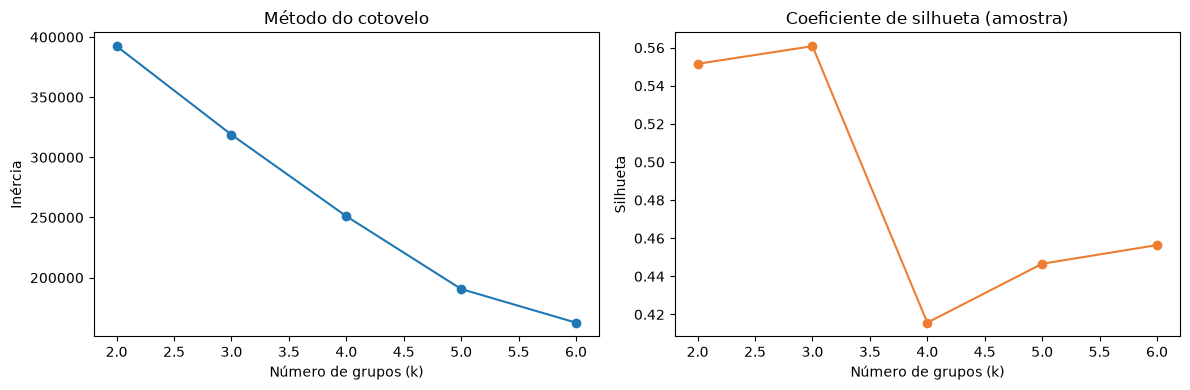

In [2]:
scaler = StandardScaler()
X_normalizado = scaler.fit_transform(X)
aleatorio = np.random.default_rng(42)
indices_amostra = aleatorio.choice(
    len(X_normalizado), size=min(3000, len(X_normalizado)), replace=False
)
resultados_k = []
modelos_k = {}
for k in range(2, 7):
    modelo_k = KMeans(n_clusters=k, n_init=10, random_state=42)
    rotulos = modelo_k.fit_predict(X_normalizado)
    silhueta = silhouette_score(
        X_normalizado[indices_amostra],
        rotulos[indices_amostra],
        metric="euclidean",
    )
    resultados_k.append({"k": k, "inercia": modelo_k.inertia_, "silhueta_amostra": silhueta})
    modelos_k[k] = modelo_k

tabela_k = pd.DataFrame(resultados_k).set_index("k")
display(tabela_k)
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
tabela_k["inercia"].plot(marker="o", ax=eixos[0])
eixos[0].set(title="Método do cotovelo", xlabel="Número de grupos (k)", ylabel="Inércia")
tabela_k["silhueta_amostra"].plot(marker="o", color="#ED7D31", ax=eixos[1])
eixos[1].set(title="Coeficiente de silhueta (amostra)", xlabel="Número de grupos (k)", ylabel="Silhueta")
fig.tight_layout()
plt.show()

A silhueta é calculada em amostra determinística de até 3.000 linhas para
manter o notebook ágil; a inércia e os ajustes usam todos os registros.
A escolha prioriza a maior silhueta e usa a curva de inércia como
verificação de ganhos decrescentes.

In [3]:
k_escolhido = int(tabela_k["silhueta_amostra"].idxmax())
modelo_perfil = modelos_k[k_escolhido]
base["grupo"] = modelo_perfil.labels_
resumo = base.groupby("grupo").agg(
    pacientes=("grupo", "size"),
    idade_media=("idade", "mean"),
    antecedencia_media=("antecedencia_media_anterior", "mean"),
    taxa_faltas_media=("taxa_faltas_anterior", "mean"),
    uso_lembrete_anterior=("taxa_lembretes_anterior", "mean"),
    consultas_anteriores_media=("n_consultas_anteriores", "mean"),
    taxa_falta_observada=("faltou", "mean"),
)
print(f"k escolhido pela maior silhueta: {k_escolhido}")
display(resumo.round(3))

k escolhido pela maior silhueta: 3


,pacientes,idade_media,antecedencia_media,taxa_faltas_media,uso_lembrete_anterior,consultas_anteriores_media,taxa_falta_observada
grupo,,,,,,,
0,19566,37.254,16.063,0.387,0.629,2.117,0.250
1,90119,36.961,0.745,0.012,0.016,0.642,0.193
2,836,47.109,0.807,0.034,0.029,36.749,0.051


## Nomes e estratégias de contato baseados nas médias

In [4]:
medianas = X.median()
perfis = {}
nomes_usados = set()
for grupo_id, linha in resumo.iterrows():
    if grupo_id == resumo["taxa_faltas_media"].idxmax():
        nome = "Histórico de faltas"
        estrategia = "Ligação da recepção 48h antes"
    elif grupo_id == resumo["consultas_anteriores_media"].idxmax():
        nome = "Acompanhamento recorrente"
        estrategia = "Manter confirmação padrão da recepção"
    elif linha["uso_lembrete_anterior"] < resumo["uso_lembrete_anterior"].median():
        nome = "Baixo uso de lembretes"
        estrategia = "Reforçar confirmação por mensagem"
    elif linha["antecedencia_media"] >= resumo["antecedencia_media"].median():
        nome = "Agendamento distante"
        estrategia = "Enviar lembrete 48h antes"
    else:
        nome = "Acompanhamento regular"
        estrategia = "Confirmação padrão da recepção"
    if nome in nomes_usados:
        nome = f"{nome} — grupo {grupo_id}"
    nomes_usados.add(nome)
    perfis[str(int(grupo_id))] = {
        "nome": nome,
        "estrategia_contato": estrategia,
    }
display(pd.DataFrame.from_dict(perfis, orient="index"))

,nome,estrategia_contato
0,Histórico de faltas,Ligação da recepção 48h antes
1,Baixo uso de lembretes,Reforçar confirmação por mensagem
2,Acompanhamento recorrente,Manter confirmação padrão da recepção


## Exportação do agrupamento e configuração

In [5]:
dump(modelo_perfil, pasta_modelos / "modelo_perfil.joblib")
dump(scaler, pasta_modelos / "scaler_perfil.joblib")
configuracao = json.loads(caminho_config.read_text(encoding="utf-8"))
configuracao["features_perfil"] = nomes_api
configuracao["agrupamento_perfil"] = {
    "algoritmo": "KMeans",
    "n_grupos": k_escolhido,
    "selecao": "maior silhueta em amostra determinística; cotovelo verificado",
    "silhueta_amostra": {
        str(int(k)): float(tabela_k.loc[k, "silhueta_amostra"])
        for k in tabela_k.index
    },
}
configuracao["perfis"] = perfis
caminho_config.write_text(json.dumps(configuracao, ensure_ascii=False, indent=2), encoding="utf-8")
print("Modelo, scaler e configuração exportados para:", pasta_modelos)

Modelo, scaler e configuração exportados para: C:\Users\User\Desktop\vagaviva-ia\modelos


## Conclusão

Os grupos e estratégias acima refletem as médias observadas; não são
rótulos clínicos nem determinam acesso ao serviço. O risco e o perfil
servem exclusivamente para organizar o contato da recepção.